# Étape 5 : Classification et priorisation

**Client :** NASA/JPL Planetary Defense Coordination Office (PDCO)
**Politique demandée :** zéro faux négatif, c'est-à-dire ne rater aucun objet potentiellement dangereux (PHA).

### Ce qu'on entraîne

| | |
|---|---|
| **Données** | Le catalogue, déjà séparé à l'étape 3 : 33 024 objets d'entraînement, 8 257 de test |
| **Entrées** | L'orbite (`a, e, i, q, ad, class`), avec ou sans les variables d'observation (`condition_code, data_arc_years, first_obs_year`) |
| **Cible** | `pha` : l'objet est-il potentiellement dangereux ? |
| **Interdits** | H et MOID, qui définissent `pha` (fuite démontrée à l'étape 3) |

### La vraie question pour la PDCO

Un modèle qui viserait 100 % de rappel n'a qu'à déclarer **tous** les objets dangereux. Ce qui compte n'est donc pas le rappel seul, mais **le prix à payer pour l'obtenir** :

> **Pour attraper 99 % des PHA, quelle part du catalogue faut-il garder sous surveillance ?**

Moins cette part est grande, plus on libère de temps de télescope. C'est la métrique métier de ce notebook.

Ce notebook utilise les données de l'étape 3 : exécutez `03_preprocessing.ipynb` avant celui-ci.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
                             precision_recall_curve, recall_score, precision_score, roc_auc_score, f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Dossier nasa-project/data/raw introuvable.")

PROJECT_DIR = find_project_dir()
PREP_DIR = PROJECT_DIR / "data" / "processed" / "03_preprocessing"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "05_classification"
REPORT_DIR = PROJECT_DIR / "reports" / "05_classification"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
if not (PREP_DIR / "classification_train.csv").exists():
    raise FileNotFoundError("Exécutez d'abord 03_preprocessing.ipynb.")

config = json.loads((PROJECT_DIR / "reports" / "03_preprocessing" / "config_preprocessing.json").read_text(encoding="utf-8"))
RANDOM_STATE = config["random_state"]
cfg = config["classification"]
TARGET = cfg["target"]
FEATURE_SETS = {
    "Orbite": cfg["features_orbit"]["numeric"] + cfg["features_orbit"]["categorical"],
    "Orbite + observation": cfg["features_orbit_obs"]["numeric"] + cfg["features_orbit_obs"]["categorical"],
}
PREPROCESSORS = {
    "Orbite": joblib.load(PREP_DIR / "preprocessor_orbit.joblib"),
    "Orbite + observation": joblib.load(PREP_DIR / "preprocessor_orbit_obs.joblib"),
}

train = pd.read_csv(PREP_DIR / "classification_train.csv")
test = pd.read_csv(PREP_DIR / "classification_test.csv")
y_train, y_test = train[TARGET].astype(int), test[TARGET].astype(int)

RECALL_TARGET = 0.99   # « zéro faux négatif » rendu opérationnel

BLUE, ORANGE, GREY, RED, GREEN = "#2878B5", "#E07A2D", "#8C8C8C", "#C0392B", "#3A8F5C"
LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}".replace(",", " ")

print(f"Train : {fmt(len(train))} objets ({y_train.sum()} PHA) | Test : {fmt(len(test))} objets ({y_test.sum()} PHA)")
print(f"Objectif de rappel : {RECALL_TARGET:.0%}")

Train : 33 024 objets (2031 PHA) | Test : 8 257 objets (508 PHA)
Objectif de rappel : 99%


## 1. Outils : seuil de décision et charge de surveillance

Un classifieur ne renvoie pas « oui / non » mais une **probabilité** d'être PHA. On choisit ensuite un **seuil** : au-dessus, l'objet est mis sous surveillance.

- Seuil par défaut (0,5) : peu d'objets signalés, mais beaucoup de PHA ratés.
- Seuil bas : presque tous les PHA sont attrapés, mais beaucoup d'objets inoffensifs aussi.

Les deux fonctions ci-dessous calculent :

- le **seuil** qui atteint le rappel visé ;
- la **charge** associée : la part du catalogue signalée à ce seuil.

In [2]:
def threshold_for_recall(y_true, proba, target):
    # Plus grand seuil qui attrape au moins `target` des PHA
    pos = np.sort(np.asarray(proba)[np.asarray(y_true) == 1])[::-1]
    k = int(np.ceil(target * len(pos))) - 1
    return float(pos[k])

def workload_curve(y_true, proba):
    # Pour chaque part du catalogue surveillée (objets triés par probabilité), le rappel obtenu
    order = np.argsort(-np.asarray(proba))
    hits = np.asarray(y_true)[order]
    share = np.arange(1, len(hits) + 1) / len(hits)
    recall = np.cumsum(hits) / hits.sum()
    return share, recall

def workload_at_recall(y_true, proba, target):
    share, recall = workload_curve(y_true, proba)
    return float(share[np.searchsorted(recall, target)])

## 2. Comparaison des modèles en validation croisée (train uniquement)

On compare, avec une validation croisée stratifiée à 5 plis sur le train :

- **Hasard** : surveiller des objets au hasard. Pour attraper 99 % des PHA, il faut surveiller 99 % du catalogue.
- **Règle simple « l'orbite croise celle de la Terre »** (périhélie q ≤ 1,05 UA et aphélie Q ≥ 0,95 UA) : une règle d'expert, sans apprentissage.
- **Arbre de décision** (profondeur 5) : lisible.
- **Random Forest** : plus performant, hyperparamètres réglés par recherche en grille.

Chaque modèle est testé avec les deux jeux de variables. `class_weight="balanced"` donne plus de poids aux PHA, qui ne représentent que 6 % des objets.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def pipe(feature_set, model):
    return Pipeline([("prep", clone(PREPROCESSORS[feature_set])), ("model", model)])

# Recherche en grille du Random Forest, critère : PR-AUC
best_rf = {}
grid_rows = []
for fs, cols in FEATURE_SETS.items():
    grid = GridSearchCV(
        pipe(fs, RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                        n_jobs=-1, random_state=RANDOM_STATE)),
        param_grid={"model__min_samples_leaf": [5, 20, 50], "model__max_features": ["sqrt", 0.6]},
        cv=cv, scoring="average_precision", n_jobs=1)
    grid.fit(train[cols], y_train)
    best_rf[fs] = grid.best_estimator_
    grid_rows.append({"jeu de variables": fs, **grid.best_params_, "PR-AUC CV": grid.best_score_})
pd.DataFrame(grid_rows).to_csv(REPORT_DIR / "grid_search_rf.csv", index=False)
pd.DataFrame(grid_rows)

,jeu de variables,model__max_features,model__min_samples_leaf,PR-AUC CV
0,Orbite,0.600,50,0.173
1,Orbite + observation,0.600,20,0.491


In [6]:
candidates = {}
for fs, cols in FEATURE_SETS.items():
    candidates[f"Arbre (prof. 5) – {fs}"] = (fs, pipe(fs, DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE)))
    candidates[f"Random Forest – {fs}"] = (fs, clone(best_rf[fs]))

oof = {}
rng = np.random.default_rng(RANDOM_STATE)
oof["Hasard"] = rng.random(len(train))
oof["Règle « croise l'orbite terrestre »"] = ((train["q"] <= 1.05) & (train["ad"] >= 0.95)).astype(float).to_numpy()
for name, (fs, model) in candidates.items():
    oof[name] = cross_val_predict(model, train[FEATURE_SETS[fs]], y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for name, p in oof.items():
    is_rule = name.startswith("Règle")
    rows.append({
        "modèle": name,
        "PR-AUC": np.nan if is_rule else average_precision_score(y_train, p),
        "ROC-AUC": np.nan if is_rule else roc_auc_score(y_train, p),
        "rappel": recall_score(y_train, p >= 0.5) if is_rule else np.nan,
        "% catalogue surveillé pour 95 % de rappel": np.nan if is_rule else workload_at_recall(y_train, p, 0.95) * 100,
        "% catalogue surveillé pour 99 % de rappel": np.nan if is_rule else workload_at_recall(y_train, p, 0.99) * 100,
        "% catalogue signalé (règle)": p.mean() * 100 if is_rule else np.nan,
    })
cv_table = pd.DataFrame(rows).set_index("modèle")
cv_table.to_csv(REPORT_DIR / "comparaison_modeles_cv.csv")
cv_table.round(3)

,PR-AUC,ROC-AUC,rappel,% catalogue surveillé pour 95 % de rappel,% catalogue surveillé pour 99 % de rappel,% catalogue signalé (règle)
modèle,,,,,,
Hasard,0.061,0.500,NaN,95.010,98.795,NaN
Règle « croise l'orbite terrestre »,NaN,NaN,0.995,NaN,NaN,73.468
Arbre (prof. 5) – Orbite,0.151,0.775,NaN,61.888,72.160,NaN
Random Forest – Orbite,0.171,0.791,NaN,58.909,71.391,NaN
Arbre (prof. 5) – Orbite + observation,0.369,0.924,NaN,24.497,55.941,NaN
Random Forest – Orbite + observation,0.487,0.943,NaN,21.578,32.295,NaN


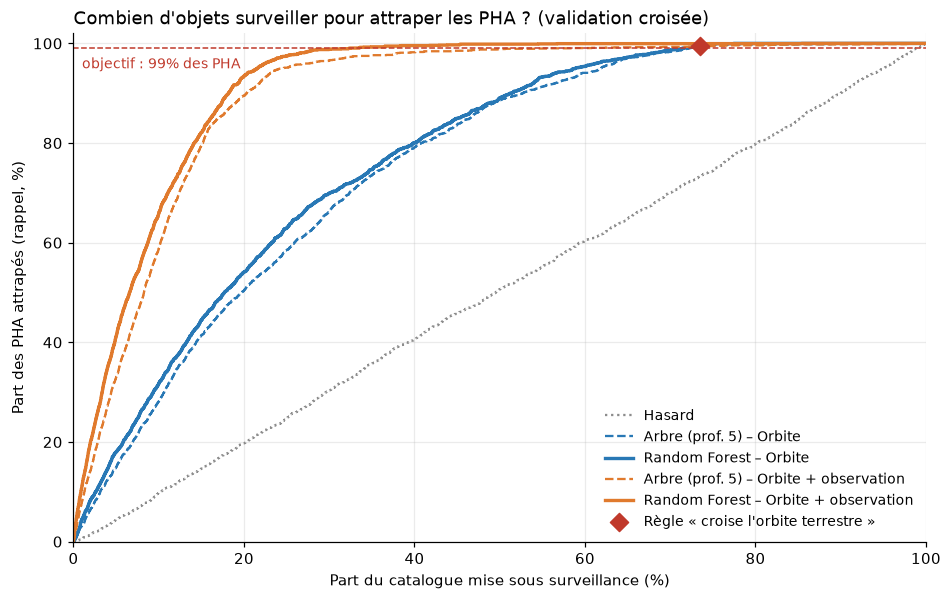

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
styles = {
    "Hasard": dict(color=GREY, ls=":", lw=1.5),
    "Arbre (prof. 5) – Orbite": dict(color=BLUE, ls="--", lw=1.5),
    "Random Forest – Orbite": dict(color=BLUE, lw=2.2),
    "Arbre (prof. 5) – Orbite + observation": dict(color=ORANGE, ls="--", lw=1.5),
    "Random Forest – Orbite + observation": dict(color=ORANGE, lw=2.2),
}
for name, st in styles.items():
    share, recall = workload_curve(y_train, oof[name])
    ax.plot(share * 100, recall * 100, label=name, **st)
rule = oof["Règle « croise l'orbite terrestre »"]
ax.scatter([rule.mean() * 100], [rule[y_train == 1].mean() * 100], marker="D", s=70, color=RED, zorder=5,
           label="Règle « croise l'orbite terrestre »")
ax.axhline(RECALL_TARGET * 100, color=RED, ls="--", lw=1)
ax.text(1, RECALL_TARGET * 100 - 4, f"objectif : {RECALL_TARGET:.0%} des PHA", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("Part du catalogue mise sous surveillance (%)")
ax.set_ylabel("Part des PHA attrapés (rappel, %)")
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_title("Combien d'objets surveiller pour attraper les PHA ? (validation croisée)", loc="left")
ax.legend(frameon=False, loc="lower right", fontsize=9)
save(fig, "courbe_rappel_charge_cv")
plt.show()

**Comment lire ce graphe :** on trie les objets du plus suspect au moins suspect, puis on avance vers la droite en mettant sous surveillance de plus en plus d'objets. La courbe indique quelle part des PHA on a déjà attrapée. **Plus une courbe monte vite, meilleur est le modèle.**

- **Hasard** (diagonale) : surveiller 50 % du catalogue n'attrape que 50 % des PHA.
- **La règle d'expert** attrape presque tous les PHA, mais elle signale près des trois quarts du catalogue : elle ne fait guère mieux que « tout surveiller ».
- **Orbite seule** : un vrai gain sur le hasard, mais pour atteindre 99 % des PHA il faut encore surveiller environ 70 % des objets.
- **Orbite + observation** : la courbe monte beaucoup plus vite. 99 % des PHA sont attrapés en surveillant environ **un tiers** du catalogue.

Rappel de l'étape 3 : une partie de ce gain vient de la taille apprise indirectement (les gros objets sont suivis plus longtemps). Ces variables sont pourtant **disponibles au moment de la décision** ; c'est donc un modèle utilisable, à condition de l'annoncer.

**Modèle retenu : Random Forest – Orbite + observation.** Le modèle « orbite seule » reste présenté comme référence sans proxy.

## 3. Choix du seuil (sur le train, en validation croisée)

Le seuil est choisi sur les probabilités **hors pli** du train, pour ne pas toucher au test : c'est le plus grand seuil qui attrape au moins 99 % des PHA.

In [6]:
CHOSEN = "Random Forest – Orbite + observation"
REFERENCE = "Random Forest – Orbite"
thresholds = {name: threshold_for_recall(y_train, oof[name], RECALL_TARGET) for name in [CHOSEN, REFERENCE]}
for name, thr in thresholds.items():
    print(f"{name} : seuil = {thr:.3f} → {np.mean(oof[name] >= thr):.1%} du train signalé")

Random Forest – Orbite + observation : seuil = 0.055 → 32.3% du train signalé
Random Forest – Orbite : seuil = 0.062 → 71.4% du train signalé


## 4. Évaluation finale sur le test (une seule fois)

Les modèles sont réentraînés sur **tout le train**, puis appliqués aux 8 257 objets du test avec le seuil choisi à la section 3.

In [7]:
final_models, test_proba = {}, {}
for name in [CHOSEN, REFERENCE]:
    fs = "Orbite + observation" if "observation" in name else "Orbite"
    final_models[name] = clone(best_rf[fs]).fit(train[FEATURE_SETS[fs]], y_train)
    test_proba[name] = final_models[name].predict_proba(test[FEATURE_SETS[fs]])[:, 1]

rows = []
for name, p in test_proba.items():
    for label, thr in [("seuil 0,5 (par défaut)", 0.5), (f"seuil {RECALL_TARGET:.0%} rappel", thresholds[name])]:
        pred = p >= thr
        rows.append({
            "modèle": name, "seuil": label, "valeur du seuil": thr,
            "rappel": recall_score(y_test, pred), "précision": precision_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred),
            "PHA ratés (FN)": int(((~pred) & (y_test == 1)).sum()),
            "% catalogue surveillé": pred.mean() * 100,
            "PR-AUC": average_precision_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, p),
        })
test_table = pd.DataFrame(rows).set_index(["modèle", "seuil"])
test_table.to_csv(REPORT_DIR / "metriques_test.csv")
test_table.round(3)

valeur du seuil  \
modèle                               seuil                                     
Random Forest – Orbite + observation seuil 0,5 (par défaut)            0.500   
                                     seuil 99% rappel                  0.055   
Random Forest – Orbite               seuil 0,5 (par défaut)            0.500   
                                     seuil 99% rappel                  0.062   

                                                             rappel  \
modèle                               seuil                            
Random Forest – Orbite + observation seuil 0,5 (par défaut)   0.872   
                                     seuil 99% rappel         0.990   
Random Forest – Orbite               seuil 0,5 (par défaut)   0.654   
                                     seuil 99% rappel         0.996   

                                                             précision    F1  \
modèle                               seuil                                     
Random Forest – Orbite + observation seuil 0,5 (par défaut)      0.305 0.452   
                                     seuil 99% rappel            0.185 0.312   
Random Forest – Orbite               seuil 0,5 (par défaut)      0.140 0.230   
                                     seuil 99% rappel            0.085 0.157   

                                                             PHA ratés (FN)  \
modèle                               seuil                                    
Random Forest – Orbite + observation seuil 0,5 (par défaut)              65   
                                     seuil 99% rappel                     5   
Random Forest – Orbite               seuil 0,5 (par défaut)             176   
                                     seuil 99% rappel                     2   

                                                             % catalogue surveillé  \
modèle                               seuil                                           
Random Forest – Orbite + observation seuil 0,5 (par défaut)                 17.609   
                                     seuil 99% rappel                       32.893   
Random Forest – Orbite               seuil 0,5 (par défaut)                 28.751   
                                     seuil 99% rappel                       72.109   

                                                             PR-AUC  ROC-AUC  
modèle                               seuil                                    
Random Forest – Orbite + observation seuil 0,5 (par défaut)   0.504    0.944  
                                     seuil 99% rappel         0.504    0.944  
Random Forest – Orbite               seuil 0,5 (par défaut)   0.165    0.784  
                                     seuil 99% rappel         0.165    0.784

**Lecture :**

- **Avec le seuil par défaut de 0,5**, le modèle retenu rate environ **13 % des PHA**. C'est incompatible avec la politique de la PDCO.
- **Avec le seuil choisi sur le train**, il atteint **99 % de rappel sur le test** : l'objectif fixé sans regarder le test est tenu. En échange, environ un tiers du catalogue est mis sous surveillance.
- **Le modèle « orbite seule »** atteint aussi 99 % de rappel, mais en signalant plus de 70 % du catalogue. Il ne fait alors guère mieux que la règle d'expert.
- **La précision reste basse** (environ 1 objet signalé sur 5 est un vrai PHA). C'est le prix assumé du « zéro faux négatif » : surveiller un objet inoffensif coûte du temps de télescope, rater un PHA peut coûter beaucoup plus.

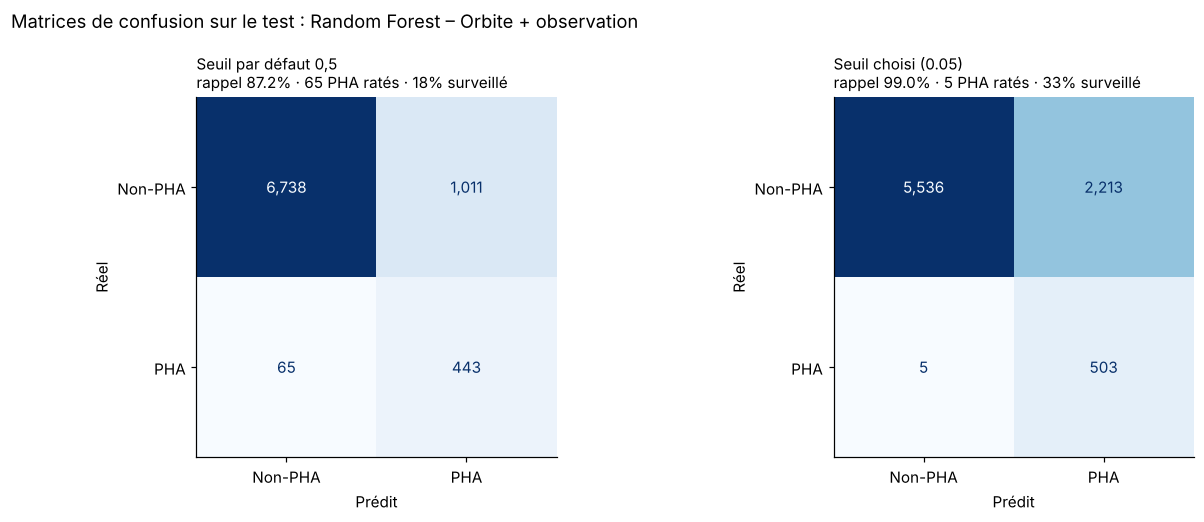

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
p = test_proba[CHOSEN]
for ax, (label, thr) in zip(axes, [("Seuil par défaut 0,5", 0.5), (f"Seuil choisi ({thresholds[CHOSEN]:.2f})", thresholds[CHOSEN])]):
    cm = confusion_matrix(y_test, p >= thr)
    ConfusionMatrixDisplay(cm, display_labels=["Non-PHA", "PHA"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",d")
    ax.set_xlabel("Prédit"); ax.set_ylabel("Réel"); ax.grid(False)
    fn, tp = cm[1, 0], cm[1, 1]
    ax.set_title(f"{label}\nrappel {tp / (tp + fn):.1%} · {fn} PHA ratés · {(p >= thr).mean():.0%} surveillé", loc="left", fontsize=10)
fig.suptitle(f"Matrices de confusion sur le test : {CHOSEN}", x=0.01, ha="left")
fig.tight_layout()
save(fig, "matrices_confusion_test")
plt.show()

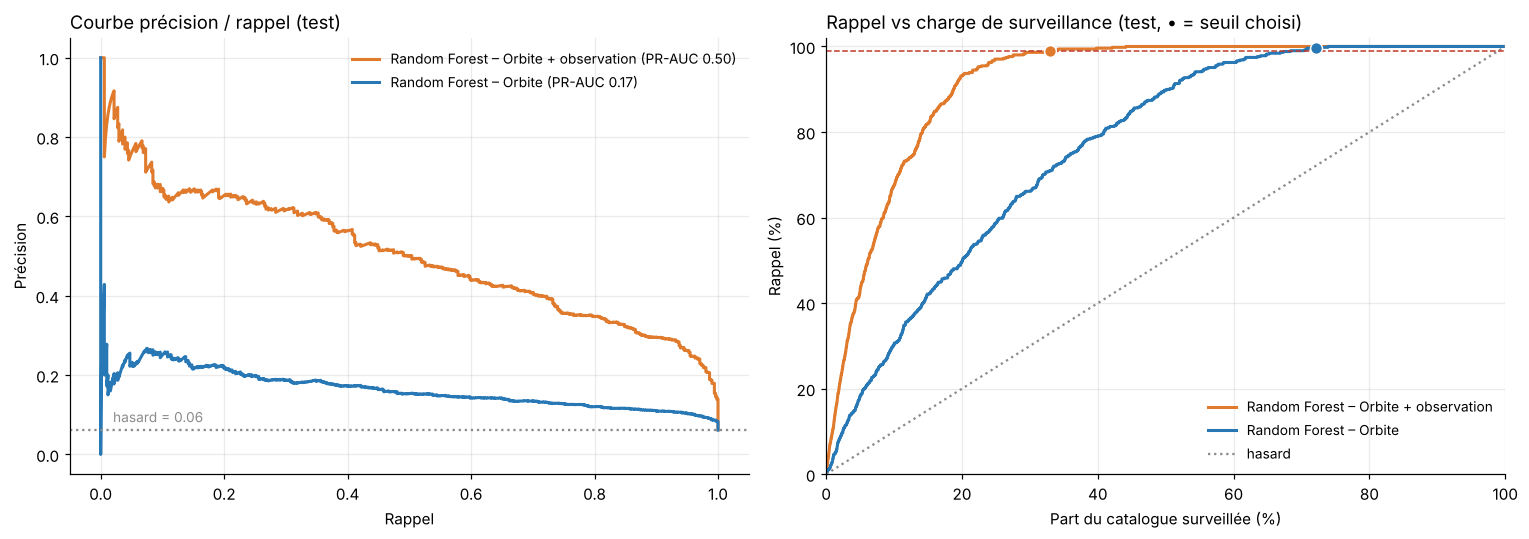

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for name, color in [(CHOSEN, ORANGE), (REFERENCE, BLUE)]:
    prec, rec, _ = precision_recall_curve(y_test, test_proba[name])
    ax.plot(rec, prec, color=color, lw=2, label=f"{name} (PR-AUC {average_precision_score(y_test, test_proba[name]):.2f})")
ax.axhline(y_test.mean(), color=GREY, ls=":", lw=1.5)
ax.text(0.02, y_test.mean() + 0.02, f"hasard = {y_test.mean():.2f}", color=GREY, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("Rappel"); ax.set_ylabel("Précision")
ax.set_title("Courbe précision / rappel (test)", loc="left")
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
for name, color in [(CHOSEN, ORANGE), (REFERENCE, BLUE)]:
    share, recall = workload_curve(y_test, test_proba[name])
    ax.plot(share * 100, recall * 100, color=color, lw=2, label=name)
    thr = thresholds[name]
    ax.scatter([np.mean(test_proba[name] >= thr) * 100], [recall_score(y_test, test_proba[name] >= thr) * 100],
               color=color, s=60, zorder=5, edgecolor="white")
ax.plot([0, 100], [0, 100], color=GREY, ls=":", lw=1.5, label="hasard")
ax.axhline(RECALL_TARGET * 100, color=RED, ls="--", lw=1)
ax.set_xlabel("Part du catalogue surveillée (%)"); ax.set_ylabel("Rappel (%)")
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_title("Rappel vs charge de surveillance (test, • = seuil choisi)", loc="left")
ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout()
save(fig, "courbes_test")
plt.show()

## 5. Qui sont les PHA ratés ?

Pour la PDCO, rater un PHA n'a pas toujours la même gravité. On regarde la taille (H) et la distance minimale à l'orbite terrestre (MOID) des PHA que le modèle n'a pas signalés. Ces colonnes ne servent **pas** au modèle ; on les utilise seulement pour analyser ses erreurs.

In [10]:
pred = test_proba[CHOSEN] >= thresholds[CHOSEN]
pha_test = test[y_test == 1].assign(signalé=pred[y_test == 1], proba=test_proba[CHOSEN][y_test == 1])
missed = pha_test[~pha_test["signalé"]]
missed[["pdes", "H", "moid_au", "a", "e", "i", "data_arc_years", "proba"]].sort_values("H").to_csv(
    REPORT_DIR / "pha_rates_test.csv", index=False)

compare = pd.DataFrame({
    "PHA signalés": pha_test[pha_test["signalé"]][["H", "moid_au", "data_arc_years"]].median(),
    "PHA ratés": missed[["H", "moid_au", "data_arc_years"]].median(),
}).rename(index={"H": "H médian", "moid_au": "MOID médian (UA)", "data_arc_years": "durée d'observation médiane (ans)"})
print(f"PHA ratés sur le test : {len(missed)} sur {len(pha_test)}")
display(missed[["pdes", "H", "moid_au", "data_arc_years", "proba"]].sort_values("data_arc_years"))
compare

PHA ratés sur le test : 5 sur 508


,pdes,H,moid_au,data_arc_years,proba
1650,2017 AG21,20.930,0.036,0.000,0.014
59,2025 SQ55,21.740,0.035,0.010,0.018
7500,2021 UV7,21.350,0.044,0.040,0.046
7727,2024 WC1,21.370,0.030,0.080,0.047
6914,756998,19.500,0.043,11.630,0.023


,PHA signalés,PHA ratés
H médian,20.530,21.350
MOID médian (UA),0.022,0.036
durée d'observation médiane (ans),10.760,0.040


**Lecture :** les PHA ratés sont presque tous des objets **découverts très récemment**, observés seulement quelques jours ou semaines. Le modèle s'appuie fortement sur la durée d'observation : un objet suivi depuis longtemps est souvent gros, donc plus souvent PHA. Un objet tout juste découvert n'a pas encore cet historique, et le modèle le sous-estime.

**Recommandation pour la PDCO :** les objets découverts récemment ont de toute façon besoin d'observations de suivi pour fixer leur orbite. Ils doivent être **surveillés systématiquement, quel que soit leur score**. Le modèle sert à trier le reste du catalogue.

## 6. Ce que le modèle a appris

**Importance par permutation** sur le test : on mélange une variable et on mesure la baisse de la PR-AUC.

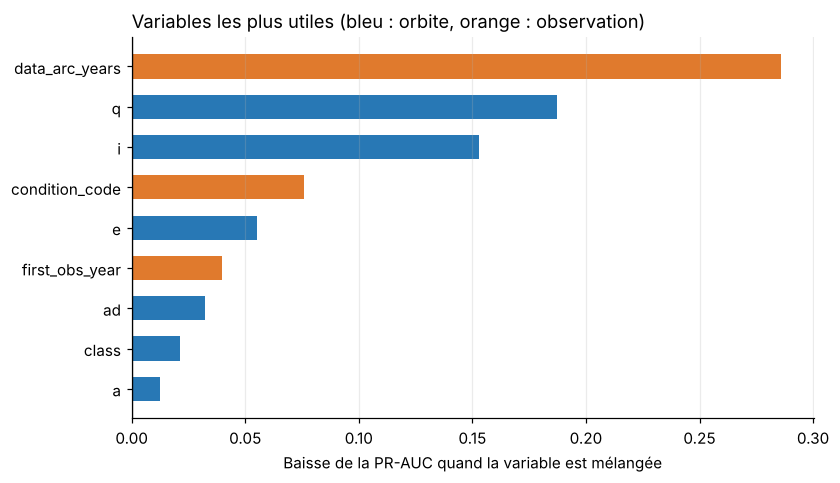

In [11]:
cols = FEATURE_SETS["Orbite + observation"]
perm = permutation_importance(final_models[CHOSEN], test[cols], y_test, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=cols).sort_values()
importance.rename("baisse de PR-AUC").to_csv(REPORT_DIR / "importance_permutation.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [ORANGE if c in cfg["features_orbit_obs"]["numeric"] and c not in cfg["features_orbit"]["numeric"] else BLUE
          for c in importance.index]
ax.barh(importance.index, importance.values, color=colors, height=0.6)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Baisse de la PR-AUC quand la variable est mélangée")
ax.set_title("Variables les plus utiles (bleu : orbite, orange : observation)", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "importance_permutation")
plt.show()

Pour la présentation, un arbre peu profond entraîné sur les variables brutes donne des **règles lisibles**. Il est moins performant que la forêt, mais montre la logique apprise.

PR-AUC de l'arbre explicatif sur le test : 0.29


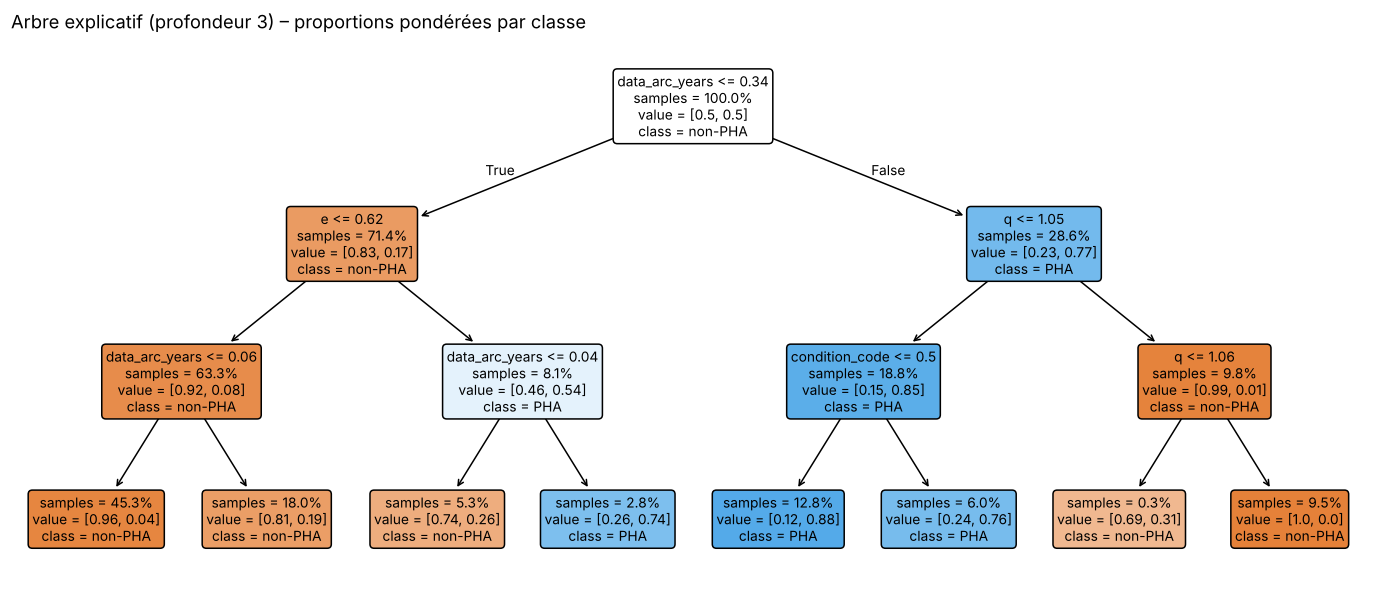

In [12]:
raw_cols = cfg["features_orbit_obs"]["numeric"]
medians = train[raw_cols].median()
explainer = DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, class_weight="balanced", random_state=RANDOM_STATE)
explainer.fit(train[raw_cols].fillna(medians), y_train)
print(f"PR-AUC de l'arbre explicatif sur le test : "
      f"{average_precision_score(y_test, explainer.predict_proba(test[raw_cols].fillna(medians))[:, 1]):.2f}")

fig, ax = plt.subplots(figsize=(16, 6.5))
plot_tree(explainer, feature_names=raw_cols, class_names=["non-PHA", "PHA"], filled=True, rounded=True,
          impurity=False, proportion=True, precision=2, fontsize=9, ax=ax)
ax.set_title("Arbre explicatif (profondeur 3) – proportions pondérées par classe", loc="left")
save(fig, "arbre_explicatif")
plt.show()

**Lecture de l'arbre** (les proportions sont rééquilibrées entre PHA et non-PHA) :

- **Première question : l'objet est-il observé depuis plus de 4 mois environ** (`data_arc_years` > 0,34) ? Les objets observés peu de temps sont surtout petits, donc rarement PHA.
- **Pour les objets suivis longtemps, la question suivante porte sur le périhélie** : si l'objet s'approche du Soleil à moins de 1,05 UA (`q ≤ 1,05`), son orbite peut croiser celle de la Terre, et il est classé PHA dans une large majorité des cas.
- **Pour les objets récents**, une orbite très allongée (`e > 0,62`) augmente le risque.

On retrouve les deux ingrédients de la définition officielle d'un PHA, mais vus indirectement : **la taille** à travers la durée d'observation, et **la proximité** à travers le périhélie.

## 7. Scores pour tout le catalogue (pour l'étape 7)

Chaque objet reçoit une probabilité d'être PHA. Pour éviter des scores trop optimistes, les objets du **train** reçoivent leur probabilité **hors pli** (calculée par un modèle qui ne les a pas vus), et ceux du **test** la probabilité du modèle final.

In [13]:
scores = pd.concat([
    pd.DataFrame({"pdes": train["pdes"], "jeu": "train",
                  "proba_pha": oof[CHOSEN], "proba_pha_orbite": oof[REFERENCE]}),
    pd.DataFrame({"pdes": test["pdes"], "jeu": "test",
                  "proba_pha": test_proba[CHOSEN], "proba_pha_orbite": test_proba[REFERENCE]}),
], ignore_index=True)
scores["signale"] = scores["proba_pha"] >= thresholds[CHOSEN]
scores.to_csv(PROCESSED_DIR / "scores_catalogue.csv", index=False)
joblib.dump(final_models[CHOSEN], PROCESSED_DIR / "rf_orbite_observation.joblib")
joblib.dump(final_models[REFERENCE], PROCESSED_DIR / "rf_orbite.joblib")
(REPORT_DIR / "seuils.json").write_text(json.dumps(
    {"recall_target": RECALL_TARGET, "thresholds": thresholds, "chosen_model": CHOSEN}, indent=2, ensure_ascii=False),
    encoding="utf-8")
print(f"{fmt(len(scores))} objets scorés, {scores['signale'].mean():.1%} signalés pour surveillance")

41 281 objets scorés, 32.4% signalés pour surveillance


## Synthèse

| Question | Réponse |
|---|---|
| Peut-on repérer un PHA sans H ni MOID ? | **Partiellement.** L'orbite seule donne un signal réel mais faible. Avec les variables d'observation, le modèle devient utile. |
| Pourquoi pas le seuil 0,5 ? | Il rate une grande partie des PHA. La politique « zéro faux négatif » impose un seuil bas, choisi pour atteindre 99 % de rappel. |
| Le prix de ce rappel | Environ un tiers du catalogue à surveiller, contre près des trois quarts avec la règle d'expert et la quasi-totalité au hasard. |
| Limite à annoncer | Les variables d'observation apportent l'essentiel du gain, en partie parce qu'elles reflètent la taille (biais de détection). |
| Pour l'étape 7 | La probabilité `proba_pha` sera combinée au diamètre pessimiste de l'étape 4 pour classer les objets par priorité. |